# Análise reprodutível de interações proteína–ligante utilizando PLIP

## Estrutura PDB 1VSN — Catepsina K / NFT

Este notebook reproduz, de forma delimitada e documentada, o perfil de interações da **pose cristalográfica** do complexo PDB `1VSN`, utilizado como exemplo por Salentin et al. (2015).

### Pergunta científica

**Quais interações não covalentes entre o ligante NFT e a catepsina K são identificadas pelo PLIP na estrutura experimental PDB 1VSN?**

### Escopo

O objetivo não é reproduzir todo o artigo de Salentin et al. (2015). A análise concentra-se na estrutura cristalográfica `1VSN` e no ligante `NFT`, avaliando o perfil de interações identificado pela versão atual do PLIP e comparando-o, dentro dos limites das informações disponíveis, com o exemplo apresentado no trabalho de referência.

### Etapas do workflow

1. Preparação do projeto e do ambiente computacional
2. Download reprodutível e verificação da identidade da estrutura PDB 1VSN
3. Inspeção da estrutura e identificação do ligante NFT
4. Análise exploratória de proximidade proteína–ligante
5. Execução do PLIP
6. Extração programática das interações
7. Construção e exportação das tabelas de resultados
8. Inspeção da estrutura protonada gerada pelo PLIP
9. Investigação de casos específicos de protonação e geometria
10. Verificação separada do contato covalente CYS25–NFT
11. Visualização e sumarização das interações
12. Investigação das moléculas de água
13. Registro do ambiente computacional
14. Testes automáticos de reprodutibilidade e verificação das interações
15. Comparação com o trabalho de referência
16. Verificação dos produtos finais
17. Avaliação da reprodutibilidade e conclusão

### Referência principal

Salentin et al. (2015). *PLIP: fully automated protein–ligand interaction profiler*. **Nucleic Acids Research**. DOI: 10.1093/nar/gkv315.

Passo 1 — Preparação do projeto
As pastas abaixo separam dados de entrada, resultados, figuras e informações do ambiente computacional.

In [1]:
import os, sys, platform, subprocess, urllib.request
from pathlib import Path

PROJECT_DIR = Path(".")
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "plip_results"
FIGURES_DIR = PROJECT_DIR / "figures"
ENV_DIR = PROJECT_DIR / "environment"

for pasta in [DATA_DIR, RESULTS_DIR, FIGURES_DIR, ENV_DIR]:
    pasta.mkdir(parents=True, exist_ok=True)

PDB_ID = "1VSN"
PDB_FILE = DATA_DIR / f"{PDB_ID}.pdb"

print("Diretórios preparados.")

Diretórios preparados.


Passo 2 — Instalação das ferramentas
O PLIP depende do Open Babel. Esta célula prepara um ambiente Google Colab compatível com o experimento.

*** Em outros sistemas operacionais, a instalação do Open Babel pode exigir procedimento específico.

In [2]:
!apt-get update -qq
!apt-get install -y openbabel
!pip install -q plip==3.0.1

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
openbabel is already the newest version (3.1.1+dfsg-9ubuntu5).
0 upgraded, 0 newly installed, 0 to remove and 28 not upgraded.


Passo 3 — Bibliotecas e versões do ambiente
As versões são registradas para tornar o experimento rastreável e facilitar comparações futuras.

In [3]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from importlib.metadata import version

def capturar_saida(comando):
    r = subprocess.run(comando, capture_output=True, text=True)
    return r.stdout.strip() or r.stderr.strip()

VERSAO_PYTHON = sys.version.split()[0]
VERSAO_PLIP = version("plip")
VERSAO_OBABEL = capturar_saida(["obabel", "-V"]).split("--")[0].replace("Open Babel", "").strip()
VERSAO_PANDAS = pd.__version__
VERSAO_NUMPY = np.__version__
VERSAO_MATPLOTLIB = matplotlib.__version__

print("Python:", VERSAO_PYTHON)
print("PLIP:", VERSAO_PLIP)
print("Open Babel:", VERSAO_OBABEL)
print("pandas:", VERSAO_PANDAS)
print("NumPy:", VERSAO_NUMPY)
print("Matplotlib:", VERSAO_MATPLOTLIB)

Python: 3.13.16
PLIP: 3.0.1
Open Babel: 3.2.1
pandas: 2.2.3
NumPy: 2.1.3
Matplotlib: 3.10.0


Passo 4 — Download da estrutura PDB 1VSN
A estrutura é obtida diretamente do Protein Data Bank e salva em data/1VSN.pdb, eliminando a necessidade de upload manual.

In [4]:
url = f"https://files.rcsb.org/download/{PDB_ID}.pdb"
urllib.request.urlretrieve(url, PDB_FILE)
assert PDB_FILE.exists()
print("Estrutura baixada:", PDB_FILE)

Estrutura baixada: data/1VSN.pdb


### Passo 4.1 — Verificação da identidade do arquivo de entrada

Para aumentar a rastreabilidade do workflow, foi calculado o hash SHA-256 do arquivo `1VSN.pdb` utilizado na análise.

O hash funciona como uma identificação do conteúdo do arquivo e permite verificar se execuções independentes utilizam exatamente o mesmo arquivo de entrada.

In [5]:
import hashlib

with open(PDB_FILE, "rb") as arquivo:
    pdb_sha256 = hashlib.sha256(arquivo.read()).hexdigest()

print("Arquivo:", PDB_FILE)
print("SHA-256:", pdb_sha256)

Arquivo: data/1VSN.pdb
SHA-256: 8418f86bba3219e160df9bc2c6bfc9061675cd2574c659c36a4db82426f7e355


**Verificação da entrada:** o hash SHA-256 obtido para `1VSN.pdb` foi
`8418f86bba3219e160df9bc2c6bfc9061675cd2574c659c36a4db82426f7e355`.

Esse valor coincide com o hash do arquivo utilizado na conferência independente realizada no PyMOL, confirmando que as análises partiram do mesmo arquivo de entrada.

Passo 5 — Inspeção inicial do PDB
O cabeçalho confirma informações gerais da estrutura. Em seguida, os registros ATOM e HETATM são separados.

In [6]:
with open(PDB_FILE, "r") as arquivo:
    linhas = arquivo.readlines()

print("Número total de linhas:", len(linhas))
for linha in linhas[:20]:
    print(linha.rstrip())

atom = [l for l in linhas if l.startswith("ATOM")]
hetatm = [l for l in linhas if l.startswith("HETATM")]

print("\nATOM:", len(atom))
print("HETATM:", len(hetatm))

Número total de linhas: 2331
HEADER    HYDROLASE                               19-MAR-07   1VSN
TITLE     CRYSTAL STRUCTURE OF A POTENT SMALL MOLECULE INHIBITOR BOUND TO
TITLE    2 CATHEPSIN K
COMPND    MOL_ID: 1;
COMPND   2 MOLECULE: CATHEPSIN K;
COMPND   3 CHAIN: A;
COMPND   4 FRAGMENT: CATHEPSIN K;
COMPND   5 SYNONYM: CATHEPSIN O, CATHEPSIN X, CATHEPSIN O2;
COMPND   6 EC: 3.4.22.38;
COMPND   7 ENGINEERED: YES
SOURCE    MOL_ID: 1;
SOURCE   2 ORGANISM_SCIENTIFIC: HOMO SAPIENS;
SOURCE   3 ORGANISM_COMMON: HUMAN;
SOURCE   4 ORGANISM_TAXID: 9606;
SOURCE   5 GENE: CTSK, CTSO, CTSO2;
SOURCE   6 EXPRESSION_SYSTEM: PICHIA PASTORIS;
SOURCE   7 EXPRESSION_SYSTEM_TAXID: 4922;
SOURCE   8 EXPRESSION_SYSTEM_STRAIN: GS 115
KEYWDS    OSTEOPOROSIS, STRUCTURE-GUIDED DRUG DESIGN, PROTEAE, HYDROLASE
EXPDTA    X-RAY DIFFRACTION

ATOM: 1615
HETATM: 302


Passo 6 — Componentes HETATM e ligante NFT
HETATM inclui componentes como ligantes e águas. O ligante NFT será isolado e organizado em um DataFrame.

In [7]:
componentes = sorted({l[17:20].strip() for l in hetatm})
print("Componentes HETATM:", componentes)

nft = [l for l in hetatm if l[17:20].strip() == "NFT"]

dados_nft = []
for l in nft:
    dados_nft.append({
        "Atom_ID": int(l[6:11]), "Atom": l[12:16].strip(),
        "Ligand": l[17:20].strip(), "Chain": l[21].strip(),
        "Residue_ID": int(l[22:26]), "X": float(l[30:38]),
        "Y": float(l[38:46]), "Z": float(l[46:54]),
        "Element": l[76:78].strip()
    })

df_nft = pd.DataFrame(dados_nft)
print("Átomos/registros do NFT:", len(df_nft))
display(df_nft)

Componentes HETATM: ['HOH', 'NFT']
Átomos/registros do NFT: 33


,Atom_ID,Atom,Ligand,Chain,Residue_ID,X,Y,Z,Element
0,1617,C46,NFT,A,283,-6.190,24.694,7.222,C
1,1618,C08,NFT,A,283,-3.965,25.609,6.583,C
2,1619,C09,NFT,A,283,-4.935,24.568,6.552,C
3,1620,C10,NFT,A,283,-4.577,23.367,5.832,C
4,1621,C11,NFT,A,283,-3.328,23.274,5.214,C
5,1622,C07,NFT,A,283,-2.692,25.499,5.958,C
6,1623,C06,NFT,A,283,-2.376,24.338,5.279,C
7,1624,C15,NFT,A,283,-1.018,24.238,4.640,C
8,1625,C16,NFT,A,283,-0.986,24.919,3.215,C
9,1626,F35,NFT,A,283,-2.039,24.558,2.442,F


Passo 7 — Resíduos próximos ao NFT
Como análise exploratória, serão identificados resíduos com pelo menos um átomo a até 5 Å do NFT.
Proximidade espacial não significa necessariamente interação molecular classificada.

In [8]:
dados_proteina = []
for l in atom:
    dados_proteina.append({
        "Atom": l[12:16].strip(), "Residue": l[17:20].strip(),
        "Chain": l[21].strip(), "Residue_ID": int(l[22:26]),
        "X": float(l[30:38]), "Y": float(l[38:46]), "Z": float(l[46:54])
    })

df_proteina = pd.DataFrame(dados_proteina)
coords_lig = df_nft[["X","Y","Z"]].to_numpy()

residuos_proximos = {}
for _, a in df_proteina.iterrows():
    coord = a[["X","Y","Z"]].to_numpy(dtype=float)
    dmin = float(np.linalg.norm(coords_lig - coord, axis=1).min())
    if dmin <= 5.0:
        chave = (a["Residue"], int(a["Residue_ID"]), a["Chain"])
        residuos_proximos[chave] = min(residuos_proximos.get(chave, np.inf), dmin)

df_proximos = pd.DataFrame([
    {"Residue":r, "Residue_ID":n, "Chain":c, "Minimum_distance_A":round(d,2)}
    for (r,n,c),d in residuos_proximos.items()
]).sort_values("Minimum_distance_A").reset_index(drop=True)

print("Resíduos a até 5 Å:", len(df_proximos))
display(df_proximos)

Resíduos a até 5 Å: 21


,Residue,Residue_ID,Chain,Minimum_distance_A
0,CYS,25,A,1.73
1,ASN,158,A,2.92
2,GLY,66,A,2.95
3,ASN,60,A,2.99
4,ASP,61,A,2.99
5,GLN,19,A,3.11
6,GLY,65,A,3.19
7,LEU,157,A,3.24
8,GLU,59,A,3.30
9,GLY,23,A,3.36


Passo 8 — Execução do PLIP
O arquivo cristalográfico original é analisado pelo PLIP. O relatório textual será a fonte primária das interações.

In [9]:
for nome in ["1VSN_report.txt", "1VSN_protonated.pdb"]:
    caminho = RESULTS_DIR / nome
    if caminho.exists():
        caminho.unlink()

r = subprocess.run(
    ["plip", "-f", str(PDB_FILE), "-o", str(RESULTS_DIR), "-t"],
    capture_output=True, text=True
)

print(r.stdout)
if r.returncode != 0:
    print(r.stderr)

assert r.returncode == 0, "A execução do PLIP falhou."
assert (RESULTS_DIR / "1VSN_report.txt").exists()
print("PLIP executado com sucesso.")


PLIP executado com sucesso.


Passo 9 — Leitura do relatório
O relatório mostra o sítio de ligação e as categorias de interação detectadas pelo PLIP.

In [10]:
REPORT_FILE = RESULTS_DIR / "1VSN_report.txt"
relatorio_plip = REPORT_FILE.read_text()
print(relatorio_plip)

Prediction of noncovalent interactions for PDB structure 1VSN
Created on 2026/10/12 using PLIP v3.0.1

If you are using PLIP in your work, please cite:
Schake,P. Bolz,SN. et al. PLIP 2025: introducing protein–protein interactions to the protein–ligand interaction profiler. Nucl. Acids Res. (10 May 2025), gkaf361. doi: 10.1093/nar/gkaf361
Analysis was done on model 1.

NFT:A:283 (NFT) - SMALLMOLECULE
-------------------------------
Interacting chain(s): A


**Hydrophobic Interactions**
+-------+---------+----------+-----------+-------------+--------------+------+--------------+---------------+-----------------------+-----------------------+
| RESNR | RESTYPE | RESCHAIN | RESNR_LIG | RESTYPE_LIG | RESCHAIN_LIG | DIST | LIGCARBONIDX | PROTCARBONIDX | LIGCOO                | PROTCOO               | 
+=======+=========+==========+===========+=============+==============+======+==============+===============+=======================+=======================+
| 61    | ASP     | A        | 283 

Passo 10 — Extração programática das interações
Para evitar transcrição manual, o notebook interpreta diretamente as tabelas do relatório.
São extraídos contatos hidrofóbicos, ligações de hidrogênio e ligações de halogênio. Para H-bonds, Distance_A corresponde à distância doador–aceitador (DIST_D-A); nas demais categorias, ao campo DIST.

In [11]:
def extrair_tabela_plip(texto, titulo):
    ls = texto.splitlines()
    try:
        idx = next(i for i,l in enumerate(ls) if l.strip() == f"**{titulo}**")
    except StopIteration:
        return []

    cabecalho, dados = None, []
    for l in ls[idx+1:]:
        s = l.strip()
        if s.startswith("**") and s.endswith("**"):
            break
        if not s.startswith("|"):
            continue
        campos = [x.strip() for x in s.strip("|").split("|")]
        if all(set(x) <= {"-"} for x in campos if x):
            continue
        if cabecalho is None:
            cabecalho = campos
        elif len(campos) == len(cabecalho):
            dados.append(dict(zip(cabecalho, campos)))
    return dados

registros = []
for titulo, tipo in [
    ("Hydrophobic Interactions", "Hydrophobic"),
    ("Hydrogen Bonds", "Hydrogen bond"),
    ("Halogen Bonds", "Halogen bond")
]:
    for x in extrair_tabela_plip(relatorio_plip, titulo):
        distancia = float(x["DIST_D-A"] if tipo == "Hydrogen bond" else x["DIST"])
        registros.append({
            "Interaction": tipo,
            "Residue": x["RESTYPE"],
            "Residue_ID": int(x["RESNR"]),
            "Chain": x["RESCHAIN"],
            "Ligand": "NFT",
            "Ligand_ID": 283,
            "Distance_A": distancia
        })

df_interacoes = pd.DataFrame(registros)
display(df_interacoes)

,Interaction,Residue,Residue_ID,Chain,Ligand,Ligand_ID,Distance_A
0,Hydrophobic,ASP,61,A,NFT,283,3.67
1,Hydrophobic,TYR,67,A,NFT,283,3.73
2,Hydrophobic,TYR,67,A,NFT,283,3.84
3,Hydrophobic,ALA,133,A,NFT,283,3.97
4,Hydrogen bond,GLN,19,A,NFT,283,3.11
5,Hydrogen bond,CYS,25,A,NFT,283,3.09
6,Hydrogen bond,ASP,61,A,NFT,283,2.99
7,Hydrogen bond,ASP,61,A,NFT,283,2.99
8,Hydrogen bond,GLY,66,A,NFT,283,3.18
9,Hydrogen bond,GLY,66,A,NFT,283,2.95


In [12]:
for titulo in [
    "Hydrophobic Interactions",
    "Hydrogen Bonds",
    "Halogen Bonds"
]:
    dados = extrair_tabela_plip(relatorio_plip, titulo)

    print("\n", titulo)
    if dados:
        print(dados[0])


 Hydrophobic Interactions
{'RESNR': '61', 'RESTYPE': 'ASP', 'RESCHAIN': 'A', 'RESNR_LIG': '283', 'RESTYPE_LIG': 'NFT', 'RESCHAIN_LIG': 'A', 'DIST': '3.67', 'LIGCARBONIDX': '1639', 'PROTCARBONIDX': '448', 'LIGCOO': '-7.395, 24.225, 6.614', 'PROTCOO': '-6.900, 21.561, 9.090'}

 Hydrogen Bonds
{'RESNR': '19', 'RESTYPE': 'GLN', 'RESCHAIN': 'A', 'RESNR_LIG': '283', 'RESTYPE_LIG': 'NFT', 'RESCHAIN_LIG': 'A', 'SIDECHAIN': 'True', 'DIST_H-A': '2.16', 'DIST_D-A': '3.11', 'DON_ANGLE': '160.05', 'PROTISDON': 'True', 'DONORIDX': '153', 'DONORTYPE': 'Nam', 'ACCEPTORIDX': '1649', 'ACCEPTORTYPE': 'N2', 'LIGCOO': '2.820, 18.145, 6.806', 'PROTCOO': '3.976, 15.409, 7.712'}

 Halogen Bonds
{'RESNR': '67', 'RESTYPE': 'TYR', 'RESCHAIN': 'A', 'RESNR_LIG': '283', 'RESTYPE_LIG': 'NFT', 'RESCHAIN_LIG': 'A', 'SIDECHAIN': 'True', 'DIST': '3.37', 'DON_ANGLE': '156.70', 'ACC_ANGLE': '100.53', 'DON_IDX': '1627', 'DONORTYPE': 'F', 'ACC_IDX': '485', 'ACCEPTORTYPE': 'O3', 'LIGCOO': '-1.005, 26.276, 3.287', 'PROTCOO':

### Passo 10.1 Tabela detalhada das interações identificadas pelo PLIP

Além da tabela resumida, foram preservados os parâmetros específicos reportados pelo PLIP para cada registro de interação.

Como diferentes classes de interação são caracterizadas por parâmetros distintos, a tabela detalhada mantém separadamente os identificadores dos átomos envolvidos, distâncias, ângulos e, quando aplicável, o papel doador–aceptor.

Essa representação permite verificar não apenas o número de registros, mas também a identidade e a geometria dos contatos classificados pelo PLIP.

In [13]:
registros_detalhados = []

# Contatos hidrofóbicos
for x in extrair_tabela_plip(relatorio_plip, "Hydrophobic Interactions"):
    registros_detalhados.append({
        "Interaction": "Hydrophobic",
        "Residue": x["RESTYPE"],
        "Residue_ID": int(x["RESNR"]),
        "Chain": x["RESCHAIN"],
        "Ligand": x["RESTYPE_LIG"],
        "Ligand_ID": int(x["RESNR_LIG"]),
        "Distance_A": float(x["DIST"]),
        "Protein_atom_ID": int(x["PROTCARBONIDX"]),
        "Ligand_atom_ID": int(x["LIGCARBONIDX"]),
        "Protein_is_donor": None,
        "Distance_HA_A": None,
        "Donor_angle_deg": None,
        "Acceptor_angle_deg": None
    })

# Ligações de hidrogênio
for x in extrair_tabela_plip(relatorio_plip, "Hydrogen Bonds"):
    registros_detalhados.append({
        "Interaction": "Hydrogen bond",
        "Residue": x["RESTYPE"],
        "Residue_ID": int(x["RESNR"]),
        "Chain": x["RESCHAIN"],
        "Ligand": x["RESTYPE_LIG"],
        "Ligand_ID": int(x["RESNR_LIG"]),
        "Distance_A": float(x["DIST_D-A"]),
        "Protein_atom_ID": (
            int(x["DONORIDX"]) if x["PROTISDON"] == "True"
            else int(x["ACCEPTORIDX"])
        ),
        "Ligand_atom_ID": (
            int(x["ACCEPTORIDX"]) if x["PROTISDON"] == "True"
            else int(x["DONORIDX"])
        ),
        "Protein_is_donor": x["PROTISDON"] == "True",
        "Distance_HA_A": float(x["DIST_H-A"]),
        "Donor_angle_deg": float(x["DON_ANGLE"]),
        "Acceptor_angle_deg": None
    })

# Ligações de halogênio
for x in extrair_tabela_plip(relatorio_plip, "Halogen Bonds"):
    registros_detalhados.append({
        "Interaction": "Halogen bond",
        "Residue": x["RESTYPE"],
        "Residue_ID": int(x["RESNR"]),
        "Chain": x["RESCHAIN"],
        "Ligand": x["RESTYPE_LIG"],
        "Ligand_ID": int(x["RESNR_LIG"]),
        "Distance_A": float(x["DIST"]),
        "Protein_atom_ID": int(x["ACC_IDX"]),
        "Ligand_atom_ID": int(x["DON_IDX"]),
        "Protein_is_donor": None,
        "Distance_HA_A": None,
        "Donor_angle_deg": float(x["DON_ANGLE"]),
        "Acceptor_angle_deg": float(x["ACC_ANGLE"])
    })

df_interacoes_detalhadas = pd.DataFrame(registros_detalhados)

display(df_interacoes_detalhadas)

,Interaction,Residue,Residue_ID,Chain,Ligand,Ligand_ID,Distance_A,Protein_atom_ID,Ligand_atom_ID,Protein_is_donor,Distance_HA_A,Donor_angle_deg,Acceptor_angle_deg
0,Hydrophobic,ASP,61,A,NFT,283,3.67,448,1639,None,NaN,NaN,NaN
1,Hydrophobic,TYR,67,A,NFT,283,3.73,482,1622,None,NaN,NaN,NaN
2,Hydrophobic,TYR,67,A,NFT,283,3.84,481,1636,None,NaN,NaN,NaN
3,Hydrophobic,ALA,133,A,NFT,283,3.97,994,1636,None,NaN,NaN,NaN
4,Hydrogen bond,GLN,19,A,NFT,283,3.11,153,1649,True,2.16,160.05,NaN
5,Hydrogen bond,CYS,25,A,NFT,283,3.09,183,1649,True,2.21,146.90,NaN
6,Hydrogen bond,ASP,61,A,NFT,283,2.99,451,1645,True,2.26,134.61,NaN
7,Hydrogen bond,ASP,61,A,NFT,283,2.99,451,1645,False,1.98,170.22,NaN
8,Hydrogen bond,GLY,66,A,NFT,283,3.18,473,1631,False,2.33,140.42,NaN
9,Hydrogen bond,GLY,66,A,NFT,283,2.95,470,1638,True,2.05,150.59,NaN


### Passo 10.2 Identificação dos átomos envolvidos nas interações

Os identificadores atômicos reportados pelo PLIP foram relacionados aos registros correspondentes do arquivo PDB de entrada.

Essa etapa permite representar os contatos por nomes de átomos, além dos identificadores numéricos, facilitando a interpretação estrutural e a comparação com medidas independentes.

In [14]:
atomos_pdb = {}

with open(PDB_FILE, "r") as arquivo:
    for linha in arquivo:
        if linha.startswith(("ATOM", "HETATM")):
            atom_id = int(linha[6:11])
            atom_name = linha[12:16].strip()
            residue = linha[17:20].strip()
            chain = linha[21].strip()
            residue_id = int(linha[22:26])

            atomos_pdb[atom_id] = {
                "Atom": atom_name,
                "Residue": residue,
                "Chain": chain,
                "Residue_ID": residue_id
            }

print("Átomos mapeados:", len(atomos_pdb))

Átomos mapeados: 1917


In [15]:
df_interacoes_detalhadas["Protein_atom"] = df_interacoes_detalhadas[
    "Protein_atom_ID"
].map(lambda x: atomos_pdb[x]["Atom"])

df_interacoes_detalhadas["Ligand_atom"] = df_interacoes_detalhadas[
    "Ligand_atom_ID"
].map(lambda x: atomos_pdb[x]["Atom"])

display(
    df_interacoes_detalhadas[
        [
            "Interaction",
            "Residue",
            "Residue_ID",
            "Protein_atom",
            "Ligand_atom",
            "Distance_A",
            "Protein_is_donor",
            "Distance_HA_A",
            "Donor_angle_deg",
            "Acceptor_angle_deg"
        ]
    ]
)

,Interaction,Residue,Residue_ID,Protein_atom,Ligand_atom,Distance_A,Protein_is_donor,Distance_HA_A,Donor_angle_deg,Acceptor_angle_deg
0,Hydrophobic,ASP,61,CB,C47,3.67,None,NaN,NaN,NaN
1,Hydrophobic,TYR,67,CE1,C07,3.73,None,NaN,NaN,NaN
2,Hydrophobic,TYR,67,CD2,C21,3.84,None,NaN,NaN,NaN
3,Hydrophobic,ALA,133,CB,C21,3.97,None,NaN,NaN,NaN
4,Hydrogen bond,GLN,19,NE2,N45,3.11,True,2.16,160.05,NaN
5,Hydrogen bond,CYS,25,N,N45,3.09,True,2.21,146.90,NaN
6,Hydrogen bond,ASP,61,OD2,N63,2.99,True,2.26,134.61,NaN
7,Hydrogen bond,ASP,61,OD2,N63,2.99,False,1.98,170.22,NaN
8,Hydrogen bond,GLY,66,O,N24,3.18,False,2.33,140.42,NaN
9,Hydrogen bond,GLY,66,N,O23,2.95,True,2.05,150.59,NaN


### Exportação da tabela detalhada

A tabela detalhada preserva os pares atômicos e os parâmetros geométricos reportados pelo PLIP.

Esse arquivo complementa a tabela resumida utilizada nas visualizações e permite verificações posteriores da identidade dos contatos, das distâncias, dos ângulos e, nas ligações de hidrogênio, da atribuição do papel doador–aceptor.

In [16]:
arquivo_detalhado = RESULTS_DIR / "interactions_1VSN_detailed.csv"

df_interacoes_detalhadas.to_csv(
    arquivo_detalhado,
    index=False
)

print("Tabela detalhada salva em:", arquivo_detalhado)

Tabela detalhada salva em: plip_results/interactions_1VSN_detailed.csv


### Investigação da estrutura protonada pelo PLIP

A classificação de ligações de hidrogênio depende não apenas das distâncias entre átomos pesados, mas também da atribuição química de doadores e aceptores e da geometria envolvendo os hidrogênios.

Como parte da análise de reprodutibilidade, foi inspecionada a estrutura protonada gerada pelo próprio PLIP (`1VSN_protonated.pdb`). Essa verificação permite distinguir a estrutura PDB experimental utilizada como entrada da estrutura preparada pelo software para a análise das interações.

In [17]:
from pathlib import Path

PROTONATED_FILE = RESULTS_DIR / "1VSN_protonated.pdb"

print("Arquivo esperado:", PROTONATED_FILE)
print("Arquivo encontrado:", PROTONATED_FILE.exists())

if PROTONATED_FILE.exists():
    print("Tamanho do arquivo:", PROTONATED_FILE.stat().st_size, "bytes")

Arquivo esperado: plip_results/1VSN_protonated.pdb
Arquivo encontrado: True
Tamanho do arquivo: 460041 bytes


In [18]:
atomos_protonados = []

with open(PROTONATED_FILE, "r") as arquivo:
    for linha in arquivo:
        if linha.startswith(("ATOM", "HETATM")):
            atom_name = linha[12:16].strip()
            residue = linha[17:20].strip()
            chain = linha[21].strip()
            residue_id = linha[22:26].strip()
            element = linha[76:78].strip()

            atomos_protonados.append({
                "Atom": atom_name,
                "Residue": residue,
                "Chain": chain,
                "Residue_ID": residue_id,
                "Element": element
            })

df_atomos_protonados = pd.DataFrame(atomos_protonados)

hidrogenios = df_atomos_protonados[
    df_atomos_protonados["Element"].str.upper() == "H"
]

print("Total de registros ATOM/HETATM:", len(df_atomos_protonados))
print("Total de hidrogênios:", len(hidrogenios))

display(hidrogenios.head(10))

Total de registros ATOM/HETATM: 2828
Total de hidrogênios: 911


,Atom,Residue,Chain,Residue_ID,Element
1917,H,ALA,A,1,H
1918,H,ALA,A,1,H
1919,H,ASP,A,3,H
1920,H,ASP,A,3,H
1921,H,SER,A,4,H
1922,H,SER,A,4,H
1923,H,ILE,A,5,H
1924,H,ASP,A,6,H
1925,H,ASP,A,6,H
1926,H,TYR,A,7,H


### Inspeção do caso ASP61–NFT N63

O relatório do PLIP contém dois registros de ligação de hidrogênio envolvendo o mesmo par de átomos, `ASP61 OD2` e `NFT N63`, com inversão do papel doador–aceptor.

Para investigar esse resultado sem tratá-lo automaticamente como dois contatos independentes, foram examinados os átomos e hidrogênios presentes nesses resíduos na estrutura protonada gerada pelo próprio PLIP.

In [19]:
asp61_protonado = df_atomos_protonados[
    (df_atomos_protonados["Residue"] == "ASP") &
    (df_atomos_protonados["Residue_ID"] == "61") &
    (df_atomos_protonados["Chain"] == "A")
]

nft283_protonado = df_atomos_protonados[
    (df_atomos_protonados["Residue"] == "NFT") &
    (df_atomos_protonados["Residue_ID"] == "283") &
    (df_atomos_protonados["Chain"] == "A")
]

print("ASP61 na estrutura protonada:")
display(asp61_protonado)

print("\nNFT283 na estrutura protonada:")
display(nft283_protonado)

ASP61 na estrutura protonada:


,Atom,Residue,Chain,Residue_ID,Element
443,N,ASP,A,61,N
444,CA,ASP,A,61,C
445,C,ASP,A,61,C
446,O,ASP,A,61,O
447,CB,ASP,A,61,C
448,CG,ASP,A,61,C
449,OD1,ASP,A,61,O
450,OD2,ASP,A,61,O
2019,H,ASP,A,61,H
2020,H,ASP,A,61,H



NFT283 na estrutura protonada:


,Atom,Residue,Chain,Residue_ID,Element
1615,C46,NFT,A,283,C
1616,C08,NFT,A,283,C
1617,C09,NFT,A,283,C
1618,C10,NFT,A,283,C
1619,C11,NFT,A,283,C
1620,C07,NFT,A,283,C
1621,C06,NFT,A,283,C
1622,C15,NFT,A,283,C
1623,C16,NFT,A,283,C
1624,F35,NFT,A,283,F


### Análise local da protonação de ASP61 OD2 e NFT N63

Para investigar os dois registros de ligação de hidrogênio entre `ASP61 OD2` e `NFT N63`, foram utilizadas as coordenadas da estrutura protonada gerada pelo PLIP.

A análise a seguir verifica quais hidrogênios estão geometricamente próximos desses átomos. Essa inspeção auxilia na interpretação da atribuição doador–aceptor, sem assumir previamente a conectividade química apenas com base no nome dos átomos.

In [20]:
atomos_protonados_coord = []

with open(PROTONATED_FILE, "r") as arquivo:
    for linha in arquivo:
        if linha.startswith(("ATOM", "HETATM")):
            atomos_protonados_coord.append({
                "Atom_ID": int(linha[6:11]),
                "Atom": linha[12:16].strip(),
                "Residue": linha[17:20].strip(),
                "Chain": linha[21].strip(),
                "Residue_ID": int(linha[22:26]),
                "X": float(linha[30:38]),
                "Y": float(linha[38:46]),
                "Z": float(linha[46:54]),
                "Element": linha[76:78].strip()
            })

df_protonado_coord = pd.DataFrame(atomos_protonados_coord)

print("Átomos com coordenadas:", len(df_protonado_coord))
display(df_protonado_coord.head())

Átomos com coordenadas: 2828


,Atom_ID,Atom,Residue,Chain,Residue_ID,X,Y,Z,Element
0,1,N,ALA,A,1,27.346,39.306,13.120,N
1,2,CA,ALA,A,1,26.736,37.958,12.921,C
2,3,C,ALA,A,1,27.753,36.939,12.322,C
3,4,O,ALA,A,1,28.466,37.273,11.366,O
4,5,CB,ALA,A,1,25.513,38.099,12.007,C


In [21]:
import numpy as np

def hidrogenios_proximos(residue, residue_id, atom_name, cutoff=1.3):
    alvo = df_protonado_coord[
        (df_protonado_coord["Residue"] == residue) &
        (df_protonado_coord["Residue_ID"] == residue_id) &
        (df_protonado_coord["Atom"] == atom_name)
    ]

    if len(alvo) != 1:
        print(f"Átomo não encontrado de forma única: {residue}{residue_id} {atom_name}")
        return pd.DataFrame()

    alvo = alvo.iloc[0]

    H = df_protonado_coord[
        df_protonado_coord["Element"].str.upper() == "H"
    ].copy()

    H["Distance_A"] = np.sqrt(
        (H["X"] - alvo["X"])**2 +
        (H["Y"] - alvo["Y"])**2 +
        (H["Z"] - alvo["Z"])**2
    )

    return H[H["Distance_A"] <= cutoff].sort_values("Distance_A")


print("Hidrogênios próximos de ASP61 OD2:")
display(
    hidrogenios_proximos(
        residue="ASP",
        residue_id=61,
        atom_name="OD2"
    )
)

print("\nHidrogênios próximos de NFT283 N63:")
display(
    hidrogenios_proximos(
        residue="NFT",
        residue_id=283,
        atom_name="N63"
    )
)

Hidrogênios próximos de ASP61 OD2:


,Atom_ID,Atom,Residue,Chain,Residue_ID,X,Y,Z,Element,Distance_A
2020,2021,H,ASP,A,61,-9.259,21.429,10.027,H,0.936667



Hidrogênios próximos de NFT283 N63:


,Atom_ID,Atom,Residue,Chain,Residue_ID,X,Y,Z,Element,Distance_A
2287,2288,H,NFT,A,283,-9.064,23.845,11.229,H,1.019691
2288,2289,H,NFT,A,283,-9.509,22.704,10.100,H,1.020251


#### Interpretação do caso ASP61–NFT N63

Na estrutura protonada gerada pelo PLIP, foi identificado um hidrogênio a aproximadamente **0,94 Å de ASP61 OD2** e dois hidrogênios a aproximadamente **1,02 Å de NFT N63**.

Esse resultado é compatível com a existência, no relatório do PLIP, de dois registros de ligação de hidrogênio envolvendo o mesmo par atômico `ASP61 OD2 ↔ NFT N63`, mas com inversão da atribuição doador–aceptor (`PROTISDON = True` e `PROTISDON = False`).

Os dois registros foram preservados como saída do PLIP, porém não são interpretados automaticamente como duas interações físicas independentes. O resultado evidencia a importância da preparação/protonação estrutural e da atribuição química de doadores e aceptores na classificação das ligações de hidrogênio.

### Inspeção do caso GLY66 O–NFT N24

A ligação de hidrogênio entre `GLY66 O` e `NFT N24` apresenta uma situação relevante para a análise da reprodutibilidade.

A distância entre os átomos pesados reportada pelo PLIP é de **3,18 Å**, valor também obtido na conferência independente. Entretanto, diferenças na orientação dos hidrogênios adicionados durante a preparação estrutural podem alterar o ângulo doador–hidrogênio–aceptor.

Por isso, a estrutura protonada gerada pelo próprio PLIP foi utilizada para examinar a geometria local desse contato.

In [22]:
gly66_o = df_protonado_coord[
    (df_protonado_coord["Residue"] == "GLY") &
    (df_protonado_coord["Residue_ID"] == 66) &
    (df_protonado_coord["Chain"] == "A") &
    (df_protonado_coord["Atom"] == "O")
]

nft_n24 = df_protonado_coord[
    (df_protonado_coord["Residue"] == "NFT") &
    (df_protonado_coord["Residue_ID"] == 283) &
    (df_protonado_coord["Chain"] == "A") &
    (df_protonado_coord["Atom"] == "N24")
]

print("GLY66 O:")
display(gly66_o)

print("\nNFT283 N24:")
display(nft_n24)

print("\nHidrogênios próximos de NFT283 N24:")
display(
    hidrogenios_proximos(
        residue="NFT",
        residue_id=283,
        atom_name="N24"
    )
)

GLY66 O:


,Atom_ID,Atom,Residue,Chain,Residue_ID,X,Y,Z,Element
472,473,O,GLY,A,66,0.194,25.01,8.576,O



NFT283 N24:


,Atom_ID,Atom,Residue,Chain,Residue_ID,X,Y,Z,Element
1629,1630,N24,NFT,A,283,0.027,24.446,5.449,N



Hidrogênios próximos de NFT283 N24:


,Atom_ID,Atom,Residue,Chain,Residue_ID,X,Y,Z,Element,Distance_A
2286,2287,H,NFT,A,283,-0.341,24.382,6.398,H,1.019863


#### Verificação geométrica do contato NFT N24–H···O GLY66

A geometria da ligação de hidrogênio foi recalculada diretamente a partir das coordenadas da estrutura protonada gerada pelo PLIP.

Foram avaliadas a distância entre doador e aceptor (D–A), a distância entre hidrogênio e aceptor (H–A) e o ângulo D–H···A. Os valores foram então comparados aos parâmetros registrados no relatório do PLIP.

In [23]:
# Coordenadas do doador: NFT N24
D = nft_n24.iloc[0][["X", "Y", "Z"]].to_numpy(dtype=float)

# Coordenadas do aceptor: GLY66 O
A = gly66_o.iloc[0][["X", "Y", "Z"]].to_numpy(dtype=float)

# Hidrogênio ligado geometricamente a NFT N24
H_df = hidrogenios_proximos(
    residue="NFT",
    residue_id=283,
    atom_name="N24"
)

H = H_df.iloc[0][["X", "Y", "Z"]].to_numpy(dtype=float)

# Distância doador–aceptor
dist_DA = np.linalg.norm(D - A)

# Distância hidrogênio–aceptor
dist_HA = np.linalg.norm(H - A)

# Ângulo D–H···A
vetor_HD = D - H
vetor_HA = A - H

cos_angulo = np.dot(vetor_HD, vetor_HA) / (
    np.linalg.norm(vetor_HD) * np.linalg.norm(vetor_HA)
)

cos_angulo = np.clip(cos_angulo, -1.0, 1.0)
angulo_DHA = np.degrees(np.arccos(cos_angulo))

print(f"Distância D–A calculada: {dist_DA:.2f} Å")
print(f"Distância H–A calculada: {dist_HA:.2f} Å")
print(f"Ângulo D–H···A calculado: {angulo_DHA:.2f}°")

print("\nValores reportados pelo PLIP:")
print("D–A: 3.18 Å")
print("H–A: 2.33 Å")
print("Ângulo: 140.42°")

Distância D–A calculada: 3.18 Å
Distância H–A calculada: 2.33 Å
Ângulo D–H···A calculado: 140.39°

Valores reportados pelo PLIP:
D–A: 3.18 Å
H–A: 2.33 Å
Ângulo: 140.42°


#### Resultado da verificação geométrica

Para o contato `NFT N24–H···O GLY66`, os parâmetros geométricos foram recalculados diretamente a partir das coordenadas de `1VSN_protonated.pdb`.

| Parâmetro | Calculado | Relatório PLIP |
|---|---:|---:|
| Distância D–A | 3,18 Å | 3,18 Å |
| Distância H–A | 2,33 Å | 2,33 Å |
| Ângulo D–H···A | 140,39° | 140,42° |

Os valores recalculados reproduzem os valores registrados pelo PLIP, com diferença angular de apenas 0,03°, compatível com arredondamento das coordenadas.

Na conferência independente realizada com uma preparação estrutural no PyMOL, a distância entre os átomos pesados também foi de aproximadamente 3,18 Å, enquanto a orientação do hidrogênio resultou em um ângulo diferente.

Assim, a distância entre os átomos pesados mostrou-se concordante entre as análises, enquanto a geometria envolvendo o hidrogênio dependeu da preparação estrutural utilizada. Esse resultado reforça a importância de documentar a protonação e a preparação da estrutura em análises de ligações de hidrogênio.

### Verificação da ligação covalente entre CYS25 e NFT

Além das interações não covalentes classificadas pelo PLIP, a estrutura contém um contato muito curto entre `CYS25 SG` e `NFT C44`.

Como esse contato não pertence ao conjunto de interações não covalentes utilizado na análise principal, ele foi avaliado separadamente. A distância entre esses dois átomos foi calculada diretamente a partir das coordenadas da estrutura de entrada.

In [24]:
# Recuperar coordenadas diretamente do PDB original
def obter_atomo_pdb(residue, residue_id, atom_name, chain="A"):
    with open(PDB_FILE, "r") as arquivo:
        for linha in arquivo:
            if linha.startswith(("ATOM", "HETATM")):
                nome = linha[12:16].strip()
                residuo = linha[17:20].strip()
                cadeia = linha[21].strip()
                numero = int(linha[22:26])

                if (
                    residuo == residue
                    and numero == residue_id
                    and nome == atom_name
                    and cadeia == chain
                ):
                    return np.array([
                        float(linha[30:38]),
                        float(linha[38:46]),
                        float(linha[46:54])
                    ])

    return None


cys25_sg = obter_atomo_pdb("CYS", 25, "SG")
nft_c44 = obter_atomo_pdb("NFT", 283, "C44")

if cys25_sg is None or nft_c44 is None:
    print("Um dos átomos não foi encontrado.")
else:
    distancia_covalente = np.linalg.norm(cys25_sg - nft_c44)

    print("CYS25 SG:", cys25_sg)
    print("NFT283 C44:", nft_c44)
    print(f"Distância CYS25 SG–NFT C44: {distancia_covalente:.2f} Å")

CYS25 SG: [ 3.847 20.506  7.225]
NFT283 C44: [ 2.699 19.401  6.542]
Distância CYS25 SG–NFT C44: 1.73 Å


#### Interpretação do contato CYS25 SG–NFT C44

A distância calculada entre `CYS25 SG` e `NFT C44` na estrutura de entrada foi de aproximadamente **1,73 Å**.

Esse contato é compatível com a ligação covalente presente entre a CYS25 e o ligante NFT e, portanto, foi registrado separadamente das interações não covalentes classificadas pelo PLIP.

Esse resultado também explica por que a análise exploratória de proximidade apresentou **1,73 Å** como a menor distância entre CYS25 e NFT. Esse valor não corresponde à ligação de hidrogênio reportada pelo PLIP para `CYS25 N ↔ NFT N45`, cuja distância doador–aceptor é de **3,09 Å**.

Assim, os dois valores descrevem pares atômicos e tipos de contato distintos:

- `CYS25 SG–NFT C44`: aproximadamente **1,73 Å** — contato covalente;
- `CYS25 N···NFT N45`: aproximadamente **3,09 Å** — registro de ligação de hidrogênio identificado pelo PLIP.

A ligação covalente não foi incluída na contagem principal dos 13 registros de interações não covalentes reportados pelo PLIP nesta análise.

### Passo 11 — Verificação e exportação da tabela de interações

Nesta etapa, são conferidas as contagens dos registros de interação e os resíduos envolvidos. Em seguida, a tabela é salva em formato CSV e relida para verificar a integridade básica do arquivo exportado.

As verificações automatizadas mais detalhadas das identidades dos pares atômicos e dos parâmetros geométricos são realizadas posteriormente no Passo 18.

In [25]:
print("Total:", len(df_interacoes))
print(df_interacoes["Interaction"].value_counts())

residuos_unicos = (
    df_interacoes[["Residue","Residue_ID","Chain"]]
    .drop_duplicates().sort_values("Residue_ID").reset_index(drop=True)
)
display(residuos_unicos)

CSV_FILE = RESULTS_DIR / "interactions_1VSN.csv"
df_interacoes.to_csv(CSV_FILE, index=False)
df_verificacao = pd.read_csv(CSV_FILE)

print("Dimensões do CSV:", df_verificacao.shape)

Total: 13
Interaction
Hydrogen bond    7
Hydrophobic      4
Halogen bond     2
Name: count, dtype: int64


,Residue,Residue_ID,Chain
0,GLN,19,A
1,CYS,25,A
2,ASP,61,A
3,GLY,66,A
4,TYR,67,A
5,ALA,133,A
6,LEU,157,A
7,ASN,158,A


Dimensões do CSV: (13, 7)


Passo 12 — Visualização por categoria
O gráfico resume o número de registros por categoria. Quantidade de registros não equivale diretamente a importância energética.

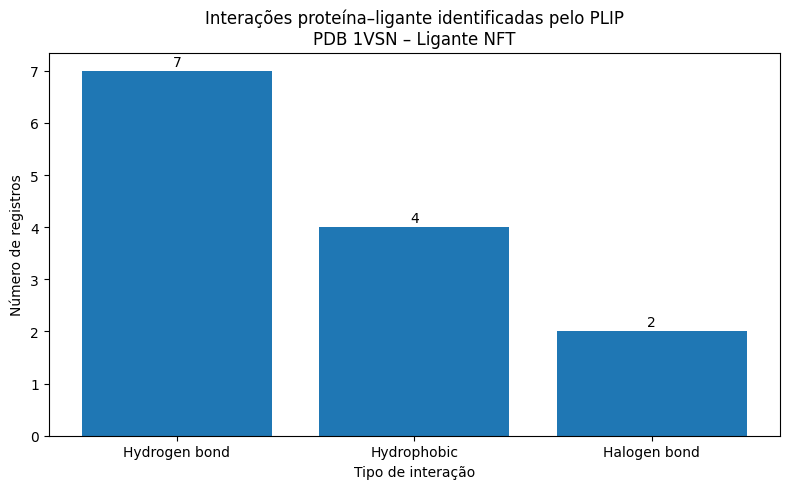

In [26]:
contagem = df_interacoes["Interaction"].value_counts()

plt.figure(figsize=(8,5))
barras = plt.bar(contagem.index, contagem.values)
plt.title("Interações proteína–ligante identificadas pelo PLIP\nPDB 1VSN – Ligante NFT")
plt.xlabel("Tipo de interação")
plt.ylabel("Número de registros")
for b in barras:
    h = b.get_height()
    plt.text(b.get_x()+b.get_width()/2, h+0.1, int(h), ha="center")
plt.tight_layout()
plt.show()

Passo 13 — Perfil de interação por resíduo

A tabela cruzada e o gráfico empilhado mostram simultaneamente qual resíduo interage e como interage.

Interaction,Halogen bond,Hydrogen bond,Hydrophobic
Residue_Label,,,
GLN19,0,1,0
CYS25,0,1,0
ASP61,0,2,1
GLY66,0,2,0
TYR67,1,0,2
ALA133,0,0,1
LEU157,1,0,0
ASN158,0,1,0


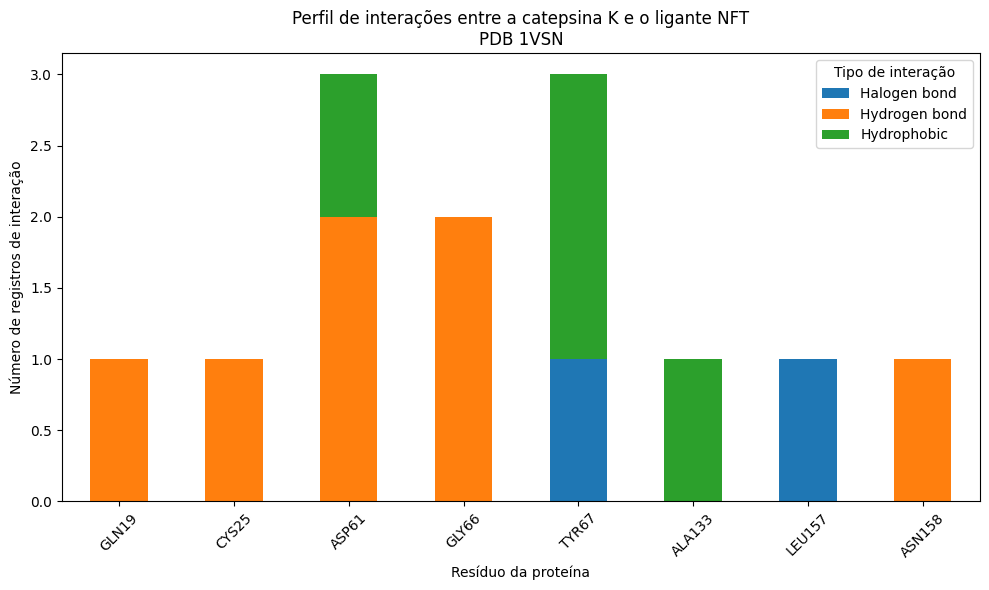

Figura salva em: figures/1VSN_interactions.png


In [27]:
df_interacoes["Residue_Label"] = df_interacoes["Residue"] + df_interacoes["Residue_ID"].astype(str)

ordem = (
    df_interacoes[["Residue_Label","Residue_ID"]]
    .drop_duplicates().sort_values("Residue_ID")["Residue_Label"]
)

tabela = pd.crosstab(df_interacoes["Residue_Label"], df_interacoes["Interaction"]).reindex(ordem)
display(tabela)

ax = tabela.plot(kind="bar", stacked=True, figsize=(10,6))
plt.title("Perfil de interações entre a catepsina K e o ligante NFT\nPDB 1VSN")
plt.xlabel("Resíduo da proteína")
plt.ylabel("Número de registros de interação")
plt.xticks(rotation=45)
plt.legend(title="Tipo de interação")
plt.tight_layout()

FIGURE_FILE = FIGURES_DIR / "1VSN_interactions.png"
plt.savefig(FIGURE_FILE, dpi=300, bbox_inches="tight")
plt.show()
print("Figura salva em:", FIGURE_FILE)

Passo 14 — Investigação das águas cristalográficas
Como a referência descreve interações mediadas por água, serão verificadas as águas presentes e aquelas a até 5 Å do NFT. Esta etapa é exploratória e não substitui os critérios químicos/angulares do PLIP.

In [28]:
aguas = [l for l in hetatm if l[17:20].strip() == "HOH"]
dados_agua = []

for l in aguas:
    dados_agua.append({
        "Residue_ID": int(l[22:26]), "Chain": l[21].strip(),
        "X": float(l[30:38]), "Y": float(l[38:46]), "Z": float(l[46:54])
    })

df_agua = pd.DataFrame(dados_agua)
aguas_proximas = []

for _, a in df_agua.iterrows():
    coord = a[["X","Y","Z"]].to_numpy(dtype=float)
    dmin = float(np.linalg.norm(coords_lig - coord, axis=1).min())
    if dmin <= 5.0:
        aguas_proximas.append({
            "Water_ID": int(a["Residue_ID"]),
            "Chain": a["Chain"],
            "Minimum_distance_A": round(dmin,2)
        })

df_aguas_proximas = pd.DataFrame(aguas_proximas).sort_values("Minimum_distance_A").reset_index(drop=True)

print("Águas cristalográficas:", len(df_agua))
print("Águas a até 5 Å:", len(df_aguas_proximas))
display(df_aguas_proximas)

Águas cristalográficas: 269
Águas a até 5 Å: 14


,Water_ID,Chain,Minimum_distance_A
0,4252,A,3.08
1,4197,A,3.26
2,4253,A,3.43
3,4260,A,3.46
4,4277,A,3.54
5,4394,A,3.55
6,4302,A,3.57
7,4259,A,3.60
8,4254,A,3.96
9,4261,A,4.08


### Passo 15 — Parâmetros de classificação de pontes de água no PLIP

A distância é apenas um dos critérios considerados pelo PLIP para classificar uma interação como `water bridge`. Além dos limites de distância, a classificação depende de requisitos geométricos e químicos, incluindo parâmetros angulares.

A seleção realizada abaixo verifica apenas quais águas atendem ao intervalo de distância configurado no PLIP 3.0.1. Portanto, estar nesse intervalo não significa que uma molécula de água tenha sido classificada como `water bridge`.

In [29]:
from plip.basic import config

print("WATER_BRIDGE_MINDIST:", config.WATER_BRIDGE_MINDIST)
print("WATER_BRIDGE_MAXDIST:", config.WATER_BRIDGE_MAXDIST)
print("WATER_BRIDGE_OMEGA_MIN:", config.WATER_BRIDGE_OMEGA_MIN)
print("WATER_BRIDGE_OMEGA_MAX:", config.WATER_BRIDGE_OMEGA_MAX)
print("WATER_BRIDGE_THETA_MIN:", config.WATER_BRIDGE_THETA_MIN)

aguas_intervalo_plip = df_aguas_proximas[
    (df_aguas_proximas["Minimum_distance_A"] >= config.WATER_BRIDGE_MINDIST) &
    (df_aguas_proximas["Minimum_distance_A"] <= config.WATER_BRIDGE_MAXDIST)
].copy()

print("\nÁguas no intervalo exploratório de distância:", len(aguas_intervalo_plip))
display(aguas_intervalo_plip)

WATER_BRIDGE_MINDIST: 2.5
WATER_BRIDGE_MAXDIST: 4.1
WATER_BRIDGE_OMEGA_MIN: 71
WATER_BRIDGE_OMEGA_MAX: 140
WATER_BRIDGE_THETA_MIN: 100

Águas no intervalo exploratório de distância: 11


,Water_ID,Chain,Minimum_distance_A
0,4252,A,3.08
1,4197,A,3.26
2,4253,A,3.43
3,4260,A,3.46
4,4277,A,3.54
5,4394,A,3.55
6,4302,A,3.57
7,4259,A,3.60
8,4254,A,3.96
9,4261,A,4.08


### Passo 16 — Interpretação da análise das águas

A estrutura contém **269 moléculas de água cristalográficas**. Pela análise espacial exploratória realizada neste notebook, **14 águas apresentam pelo menos um átomo a até 5 Å de qualquer átomo do ligante NFT**.

Dessas 14 águas, **11 apresentam distância mínima dentro do intervalo de 2,5–4,1 Å** observado nas configurações do PLIP 3.0.1 para `water bridges`. Esse resultado indica apenas que essas águas atendem ao intervalo de distância examinado; **não significa que tenham sido classificadas como pontes de água**.

Na execução atual, o PLIP 3.0.1 reportou **0 `water bridges`**. Isso reforça que a distância, isoladamente, não é suficiente para caracterizar esse tipo de interação, cuja classificação também depende de requisitos químicos e geométricos.

A ausência de `water bridges` é, portanto, registrada como uma **diferença observada em relação ao trabalho de referência**. A causa específica dessa divergência não foi determinada neste experimento.

### Passo 17 — Registro do ambiente computacional

Para aumentar a rastreabilidade do workflow, são registradas as versões do Python, PLIP, Open Babel, pandas, NumPy e Matplotlib utilizadas nesta execução.

O arquivo `environment_versions.txt` documenta as versões observadas no ambiente de execução, enquanto `requirements.txt` fixa as principais dependências Python utilizadas pelo notebook.

Esse registro favorece a reprodutibilidade computacional, mas não garante, isoladamente, a reconstrução futura exata do ambiente. Dependências de sistema, bibliotecas transitivas, versões do sistema operacional e alterações na imagem-base do Google Colab também podem influenciar a execução. O Open Babel, em particular, é uma dependência de sistema e não é instalado pelo arquivo `requirements.txt`.

In [30]:
ambiente = f"""Ambiente computacional - Análise PLIP 1VSN

Python: {VERSAO_PYTHON}
PLIP: {VERSAO_PLIP}
Open Babel: {VERSAO_OBABEL}
pandas: {VERSAO_PANDAS}
NumPy: {VERSAO_NUMPY}
Matplotlib: {VERSAO_MATPLOTLIB}
"""
(ENV_DIR / "environment_versions.txt").write_text(ambiente)

requirements = f"""plip=={VERSAO_PLIP}
pandas=={VERSAO_PANDAS}
numpy=={VERSAO_NUMPY}
matplotlib=={VERSAO_MATPLOTLIB}
"""
(ENV_DIR / "requirements.txt").write_text(requirements)

print(ambiente)

Ambiente computacional - Análise PLIP 1VSN

Python: 3.13.16
PLIP: 3.0.1
Open Babel: 3.2.1
pandas: 2.2.3
NumPy: 2.1.3
Matplotlib: 3.10.0



### Passo 18 — Testes automáticos de reprodutibilidade

Os testes verificam se a execução reproduz os resultados computacionais esperados do workflow, incluindo contagens, identidades dos pares atômicos e parâmetros geométricos das interações.

Esses testes funcionam como controles internos de consistência e reprodutibilidade computacional. Eles permitem detectar alterações inesperadas nos resultados durante uma nova execução, mas não constituem validação experimental das interações moleculares.

In [31]:
df_teste = pd.read_csv(CSV_FILE)
c = df_teste["Interaction"].value_counts()

assert len(df_teste) == 13
assert int(c.get("Hydrogen bond", 0)) == 7
assert int(c.get("Hydrophobic", 0)) == 4
assert int(c.get("Halogen bond", 0)) == 2
assert df_teste[["Residue","Residue_ID","Chain"]].drop_duplicates().shape[0] == 8
assert len(df_agua) == 269
assert len(df_aguas_proximas) == 14
assert len(aguas_intervalo_plip) == 11

print("Todos os testes foram aprovados.")

Todos os testes foram aprovados.


### Passo 18.1 — Verificação da identidade das interações

Além da verificação das contagens globais, foram adicionados testes para confirmar a identidade dos pares atômicos detectados.

Essa validação é importante porque duas análises podem apresentar o mesmo número total de interações, mas envolver contatos diferentes. Portanto, a reprodutibilidade foi avaliada também no nível dos resíduos e átomos participantes.

In [32]:
# Selecionar apenas os contatos hidrofóbicos da tabela detalhada
hidrofobicas_teste = df_interacoes_detalhadas[
    df_interacoes_detalhadas["Interaction"] == "Hydrophobic"
]

# Pares atômicos esperados
pares_hidrofobicos_esperados = {
    ("ASP", 61, "CB", "C47"),
    ("TYR", 67, "CE1", "C07"),
    ("TYR", 67, "CD2", "C21"),
    ("ALA", 133, "CB", "C21"),
}

# Pares encontrados pelo workflow
pares_hidrofobicos_obtidos = set(
    zip(
        hidrofobicas_teste["Residue"],
        hidrofobicas_teste["Residue_ID"],
        hidrofobicas_teste["Protein_atom"],
        hidrofobicas_teste["Ligand_atom"],
    )
)

print("Pares esperados:")
print(pares_hidrofobicos_esperados)

print("\nPares obtidos:")
print(pares_hidrofobicos_obtidos)

assert pares_hidrofobicos_obtidos == pares_hidrofobicos_esperados

print("\nTeste dos pares hidrofóbicos aprovado.")

Pares esperados:
{('ALA', 133, 'CB', 'C21'), ('TYR', 67, 'CD2', 'C21'), ('TYR', 67, 'CE1', 'C07'), ('ASP', 61, 'CB', 'C47')}

Pares obtidos:
{('ALA', 133, 'CB', 'C21'), ('TYR', 67, 'CD2', 'C21'), ('TYR', 67, 'CE1', 'C07'), ('ASP', 61, 'CB', 'C47')}

Teste dos pares hidrofóbicos aprovado.


In [33]:
# Distâncias esperadas para os contatos hidrofóbicos
distancias_hidrofobicas_esperadas = {
    ("ASP", 61, "CB", "C47"): 3.67,
    ("TYR", 67, "CE1", "C07"): 3.73,
    ("TYR", 67, "CD2", "C21"): 3.84,
    ("ALA", 133, "CB", "C21"): 3.97,
}

print("Validação das distâncias dos contatos hidrofóbicos:\n")

for _, linha in hidrofobicas_teste.iterrows():

    par = (
        linha["Residue"],
        int(linha["Residue_ID"]),
        linha["Protein_atom"],
        linha["Ligand_atom"],
    )

    distancia_obtida = float(linha["Distance_A"])
    distancia_esperada = distancias_hidrofobicas_esperadas[par]

    diferenca = abs(distancia_obtida - distancia_esperada)

    print(
        f"{linha['Residue']}{int(linha['Residue_ID'])} "
        f"{linha['Protein_atom']}–NFT {linha['Ligand_atom']}: "
        f"obtido = {distancia_obtida:.2f} Å | "
        f"esperado = {distancia_esperada:.2f} Å | "
        f"diferença = {diferenca:.3f} Å"
    )

    assert np.isclose(
        distancia_obtida,
        distancia_esperada,
        atol=0.01
    )

print("\nTeste das distâncias hidrofóbicas aprovado.")

Validação das distâncias dos contatos hidrofóbicos:

ASP61 CB–NFT C47: obtido = 3.67 Å | esperado = 3.67 Å | diferença = 0.000 Å
TYR67 CE1–NFT C07: obtido = 3.73 Å | esperado = 3.73 Å | diferença = 0.000 Å
TYR67 CD2–NFT C21: obtido = 3.84 Å | esperado = 3.84 Å | diferença = 0.000 Å
ALA133 CB–NFT C21: obtido = 3.97 Å | esperado = 3.97 Å | diferença = 0.000 Å

Teste das distâncias hidrofóbicas aprovado.


In [34]:
# Selecionar as ligações de halogênio
halogenios_teste = df_interacoes_detalhadas[
    df_interacoes_detalhadas["Interaction"] == "Halogen bond"
]

# Valores esperados:
# (resíduo, número, átomo proteína, átomo ligante)
# -> (distância, ângulo doador, ângulo aceptor)

halogenios_esperados = {
    ("TYR", 67, "OH", "F36"): (3.37, 156.70, 100.53),
    ("LEU", 157, "O", "F37"): (3.24, 141.32, 129.13),
}

pares_halogenio_obtidos = set(
    zip(
        halogenios_teste["Residue"],
        halogenios_teste["Residue_ID"],
        halogenios_teste["Protein_atom"],
        halogenios_teste["Ligand_atom"],
    )
)

pares_halogenio_esperados = set(halogenios_esperados.keys())

print("Pares esperados:")
print(pares_halogenio_esperados)

print("\nPares obtidos:")
print(pares_halogenio_obtidos)

assert pares_halogenio_obtidos == pares_halogenio_esperados

print("\nValidação geométrica:\n")

for _, linha in halogenios_teste.iterrows():

    par = (
        linha["Residue"],
        int(linha["Residue_ID"]),
        linha["Protein_atom"],
        linha["Ligand_atom"],
    )

    dist_esp, ang_doador_esp, ang_aceptor_esp = halogenios_esperados[par]

    dist_obt = float(linha["Distance_A"])
    ang_doador_obt = float(linha["Donor_angle_deg"])
    ang_aceptor_obt = float(linha["Acceptor_angle_deg"])

    print(
        f"{linha['Residue']}{int(linha['Residue_ID'])} "
        f"{linha['Protein_atom']}–NFT {linha['Ligand_atom']}\n"
        f"  Distância: {dist_obt:.2f} Å (esperado {dist_esp:.2f} Å)\n"
        f"  Ângulo doador: {ang_doador_obt:.2f}° "
        f"(esperado {ang_doador_esp:.2f}°)\n"
        f"  Ângulo aceptor: {ang_aceptor_obt:.2f}° "
        f"(esperado {ang_aceptor_esp:.2f}°)\n"
    )

    assert np.isclose(dist_obt, dist_esp, atol=0.01)
    assert np.isclose(ang_doador_obt, ang_doador_esp, atol=0.05)
    assert np.isclose(ang_aceptor_obt, ang_aceptor_esp, atol=0.05)

print("Teste das ligações de halogênio aprovado.")

Pares esperados:
{('LEU', 157, 'O', 'F37'), ('TYR', 67, 'OH', 'F36')}

Pares obtidos:
{('LEU', 157, 'O', 'F37'), ('TYR', 67, 'OH', 'F36')}

Validação geométrica:

TYR67 OH–NFT F36
  Distância: 3.37 Å (esperado 3.37 Å)
  Ângulo doador: 156.70° (esperado 156.70°)
  Ângulo aceptor: 100.53° (esperado 100.53°)

LEU157 O–NFT F37
  Distância: 3.24 Å (esperado 3.24 Å)
  Ângulo doador: 141.32° (esperado 141.32°)
  Ângulo aceptor: 129.13° (esperado 129.13°)

Teste das ligações de halogênio aprovado.


In [35]:
# Selecionar as ligações de hidrogênio
hbonds_teste = df_interacoes_detalhadas[
    df_interacoes_detalhadas["Interaction"] == "Hydrogen bond"
].copy()

# Registros esperados:
# (resíduo, número, átomo proteína, átomo ligante, proteína é doadora?)
# -> (distância D-A, distância H-A, ângulo D-H-A)

hbonds_esperados = {
    ("GLN", 19, "NE2", "N45", True):  (3.11, 2.16, 160.05),
    ("CYS", 25, "N",   "N45", True):  (3.09, 2.21, 146.90),
    ("ASP", 61, "OD2", "N63", True):  (2.99, 2.26, 134.61),
    ("ASP", 61, "OD2", "N63", False): (2.99, 1.98, 170.22),
    ("GLY", 66, "O",   "N24", False): (3.18, 2.33, 140.42),
    ("GLY", 66, "N",   "O23", True):  (2.95, 2.05, 150.59),
    ("ASN", 158, "O",  "N26", False): (2.92, 1.95, 167.45),
}

# Normalizar a coluna Protein_is_donor caso ela tenha sido lida como texto
def converter_bool(valor):
    if isinstance(valor, bool):
        return valor
    return str(valor).strip().lower() == "true"

hbonds_teste["Protein_is_donor_bool"] = (
    hbonds_teste["Protein_is_donor"].apply(converter_bool)
)

registros_obtidos = set(
    zip(
        hbonds_teste["Residue"],
        hbonds_teste["Residue_ID"].astype(int),
        hbonds_teste["Protein_atom"],
        hbonds_teste["Ligand_atom"],
        hbonds_teste["Protein_is_donor_bool"],
    )
)

registros_esperados = set(hbonds_esperados.keys())

print("Número de registros esperados:", len(registros_esperados))
print("Número de registros obtidos:", len(registros_obtidos))

assert registros_obtidos == registros_esperados

print("\nIdentidade dos 7 registros de ligação de hidrogênio aprovada.")

Número de registros esperados: 7
Número de registros obtidos: 7

Identidade dos 7 registros de ligação de hidrogênio aprovada.


In [36]:
print("Validação geométrica das ligações de hidrogênio:\n")

for _, linha in hbonds_teste.iterrows():

    par = (
        linha["Residue"],
        int(linha["Residue_ID"]),
        linha["Protein_atom"],
        linha["Ligand_atom"],
        linha["Protein_is_donor_bool"],
    )

    dist_DA_esp, dist_HA_esp, angulo_esp = hbonds_esperados[par]

    dist_DA_obt = float(linha["Distance_A"])
    dist_HA_obt = float(linha["Distance_HA_A"])
    angulo_obt = float(linha["Donor_angle_deg"])

    papel = (
        "proteína doadora"
        if linha["Protein_is_donor_bool"]
        else "ligante doador"
    )

    print(
        f"{linha['Residue']}{int(linha['Residue_ID'])} "
        f"{linha['Protein_atom']}–NFT {linha['Ligand_atom']} "
        f"({papel})\n"
        f"  D–A: {dist_DA_obt:.2f} Å "
        f"(esperado {dist_DA_esp:.2f} Å)\n"
        f"  H–A: {dist_HA_obt:.2f} Å "
        f"(esperado {dist_HA_esp:.2f} Å)\n"
        f"  Ângulo D–H···A: {angulo_obt:.2f}° "
        f"(esperado {angulo_esp:.2f}°)\n"
    )

    assert np.isclose(
        dist_DA_obt,
        dist_DA_esp,
        atol=0.01
    )

    assert np.isclose(
        dist_HA_obt,
        dist_HA_esp,
        atol=0.01
    )

    assert np.isclose(
        angulo_obt,
        angulo_esp,
        atol=0.05
    )

print("Teste geométrico das ligações de hidrogênio aprovado.")

Validação geométrica das ligações de hidrogênio:

GLN19 NE2–NFT N45 (proteína doadora)
  D–A: 3.11 Å (esperado 3.11 Å)
  H–A: 2.16 Å (esperado 2.16 Å)
  Ângulo D–H···A: 160.05° (esperado 160.05°)

CYS25 N–NFT N45 (proteína doadora)
  D–A: 3.09 Å (esperado 3.09 Å)
  H–A: 2.21 Å (esperado 2.21 Å)
  Ângulo D–H···A: 146.90° (esperado 146.90°)

ASP61 OD2–NFT N63 (proteína doadora)
  D–A: 2.99 Å (esperado 2.99 Å)
  H–A: 2.26 Å (esperado 2.26 Å)
  Ângulo D–H···A: 134.61° (esperado 134.61°)

ASP61 OD2–NFT N63 (ligante doador)
  D–A: 2.99 Å (esperado 2.99 Å)
  H–A: 1.98 Å (esperado 1.98 Å)
  Ângulo D–H···A: 170.22° (esperado 170.22°)

GLY66 O–NFT N24 (ligante doador)
  D–A: 3.18 Å (esperado 3.18 Å)
  H–A: 2.33 Å (esperado 2.33 Å)
  Ângulo D–H···A: 140.42° (esperado 140.42°)

GLY66 N–NFT O23 (proteína doadora)
  D–A: 2.95 Å (esperado 2.95 Å)
  H–A: 2.05 Å (esperado 2.05 Å)
  Ângulo D–H···A: 150.59° (esperado 150.59°)

ASN158 O–NFT N26 (ligante doador)
  D–A: 2.92 Å (esperado 2.92 Å)
  H–A: 1.95 

### Verificação automatizada das interações

Os testes de reprodutibilidade foram ampliados para verificar não apenas as contagens globais, mas também a identidade dos pares atômicos e seus parâmetros geométricos.

Foram verificados:

- **4 contatos hidrofóbicos**, incluindo os pares atômicos e suas distâncias;
- **2 ligações de halogênio**, incluindo os pares atômicos, distâncias e ângulos;
- **7 registros de ligações de hidrogênio**, incluindo os pares atômicos, os papéis de doador/aceptor, as distâncias D–A e H–A e os ângulos D–H···A.

No caso de `ASP61 OD2 ↔ NFT N63`, os dois registros produzidos pelo PLIP foram preservados separadamente porque apresentam os papéis de doador/aceptor invertidos. Esses registros não são interpretados automaticamente como duas ligações de hidrogênio físicas independentes.

Adicionalmente, a geometria do contato `NFT N24–H···O GLY66` foi recalculada diretamente a partir da estrutura protonada gerada pelo PLIP. Foram obtidos **3,18 Å** para D–A, **2,33 Å** para H–A e **140,39°** para o ângulo D–H···A, em concordância com os valores do relatório do PLIP (**3,18 Å**, **2,33 Å** e **140,42°**, respectivamente).

Essas verificações avaliam a **consistência interna e a reprodutibilidade computacional do workflow** para os contatos analisados. Elas não constituem validação experimental das interações moleculares.

## Comparação com o trabalho de referência

A reprodução científica foi avaliada por comparação com o exemplo de `1VSN` apresentado por Salentin et al. (2015).

O artigo utiliza a estrutura cristalográfica do complexo catepsina K–NFT e apresenta o perfil de interações proteína–ligante identificado pelo PLIP, destacando diferentes classes de contatos, incluindo interações hidrofóbicas, ligações de hidrogênio, ligações de halogênio e interações mediadas por água.

Como o trabalho de referência não fornece, para esse exemplo, uma tabela completa com todos os pares atômicos e parâmetros geométricos equivalente ao relatório produzido pela versão atual do PLIP, a comparação com o artigo é realizada principalmente no nível das classes de interação e das características explicitamente descritas pelos autores.

In [37]:
comparacao_referencia = pd.DataFrame([
    {
        "Característica": "Estrutura analisada",
        "Salentin et al. (2015)": "PDB 1VSN, pose cristalográfica",
        "PLIP 3.0.1 (este trabalho)": "PDB 1VSN, pose cristalográfica",
        "Comparação": "Concordância"
    },
    {
        "Característica": "Contatos hidrofóbicos",
        "Salentin et al. (2015)": "Representados no perfil de interação",
        "PLIP 3.0.1 (este trabalho)": "4 registros",
        "Comparação": "Concordância qualitativa"
    },
    {
        "Característica": "Ligações de hidrogênio",
        "Salentin et al. (2015)": "Representadas no perfil de interação",
        "PLIP 3.0.1 (este trabalho)": "7 registros",
        "Comparação": "Concordância qualitativa"
    },
    {
        "Característica": "Ligações de halogênio",
        "Salentin et al. (2015)": "Destacadas pelos autores",
        "PLIP 3.0.1 (este trabalho)": "2 registros",
        "Comparação": "Concordância qualitativa"
    },
    {
        "Característica": "Interações mediadas por água",
        "Salentin et al. (2015)": "Descritas no exemplo",
        "PLIP 3.0.1 (este trabalho)": "0 pontes de água classificadas",
        "Comparação": "Divergência"
    },
])

display(comparacao_referencia)

,Característica,Salentin et al. (2015),PLIP 3.0.1 (este trabalho),Comparação
0,Estrutura analisada,"PDB 1VSN, pose cristalográfica","PDB 1VSN, pose cristalográfica",Concordância
1,Contatos hidrofóbicos,Representados no perfil de interação,4 registros,Concordância qualitativa
2,Ligações de hidrogênio,Representadas no perfil de interação,7 registros,Concordância qualitativa
3,Ligações de halogênio,Destacadas pelos autores,2 registros,Concordância qualitativa
4,Interações mediadas por água,Descritas no exemplo,0 pontes de água classificadas,Divergência


### Interpretação da comparação com Salentin et al. (2015)

A comparação com o trabalho de referência indica uma **reprodução parcial do perfil de interações da pose cristalográfica de 1VSN**.

A análise realizada com o PLIP 3.0.1 recuperou classes de interação relevantes também apresentadas no exemplo de Salentin et al. (2015), incluindo contatos hidrofóbicos, ligações de hidrogênio e ligações de halogênio. As ligações de halogênio constituem um ponto particularmente relevante de concordância qualitativa, pois esse tipo de interação é destacado pelos autores na discussão do complexo.

Entretanto, a reprodução não foi completa. Enquanto o trabalho de referência descreve interações mediadas por moléculas de água, a execução atual do PLIP não classificou nenhuma interação como `water bridge`.

Essa ausência não pode ser interpretada simplesmente como ausência de moléculas de água próximas ao ligante. A estrutura analisada contém moléculas de água cristalográficas, incluindo águas espacialmente próximas ao NFT. Para que uma molécula de água seja classificada pelo PLIP como ponte de água, entretanto, não basta a proximidade: ela deve satisfazer simultaneamente os critérios químicos e geométricos utilizados pelo algoritmo.

As diferenças observadas entre o trabalho de referência e a análise atual podem estar relacionadas a fatores como versão do software, preparação estrutural, protonação e critérios geométricos de classificação. No presente trabalho, entretanto, não foi estabelecida experimental ou computacionalmente uma causa única para a divergência nas pontes de água.

Portanto, os resultados sustentam uma **reprodução parcial**, com concordância qualitativa em classes importantes de interação e uma divergência observável na detecção de interações mediadas por água.

### Observação sobre a análise das moléculas de água

A análise exploratória deste notebook identificou **269 moléculas de água** na estrutura e **14 águas com pelo menos um átomo a até 5 Å de qualquer átomo do ligante NFT**.

Esse critério de proximidade foi utilizado apenas como uma análise espacial exploratória. Ele não corresponde, por si só, ao critério utilizado pelo PLIP para classificar uma molécula de água como `water bridge`.

Além disso, essa seleção não deve ser comparada diretamente com inspeções realizadas utilizando subconjuntos específicos de átomos do ligante, pois diferentes critérios de seleção podem produzir conjuntos distintos de moléculas de água próximas.

Mesmo entre as águas localizadas na vizinhança do NFT, a proximidade espacial não é suficiente para caracterizar uma ponte de água. A classificação depende também da geometria e dos papéis químicos dos átomos envolvidos na interação proteína–água–ligante.

Na execução atual, **nenhuma `water bridge` foi classificada pelo PLIP 3.0.1**. Portanto, as águas próximas identificadas neste notebook devem ser interpretadas como **candidatas espaciais para investigação**, e não como pontes de água confirmadas.

### Passo 19 — Verificação dos produtos finais

Esta etapa verifica se os principais artefatos esperados do workflow foram efetivamente gerados, incluindo os arquivos de entrada, resultados do PLIP, tabelas de interações, figura e registros do ambiente computacional.

A existência desses arquivos confirma a completude operacional da execução, mas não constitui, isoladamente, validação científica de seu conteúdo.

In [38]:
arquivos = [
    DATA_DIR/"1VSN.pdb",
    RESULTS_DIR/"1VSN_report.txt",
    RESULTS_DIR/"1VSN_protonated.pdb",
    RESULTS_DIR/"interactions_1VSN.csv",
    RESULTS_DIR/"interactions_1VSN_detailed.csv",
    FIGURES_DIR/"1VSN_interactions.png",
    ENV_DIR/"environment_versions.txt",
    ENV_DIR/"requirements.txt"
]

for a in arquivos:
    print(("OK" if a.exists() else "AUSENTE").ljust(8), "|", a)

assert all(a.exists() for a in arquivos)

print("\nTodos os arquivos esperados foram gerados.")

OK       | data/1VSN.pdb
OK       | plip_results/1VSN_report.txt
OK       | plip_results/1VSN_protonated.pdb
OK       | plip_results/interactions_1VSN.csv
OK       | plip_results/interactions_1VSN_detailed.csv
OK       | figures/1VSN_interactions.png
OK       | environment/environment_versions.txt
OK       | environment/requirements.txt

Todos os arquivos esperados foram gerados.


# Conclusão — análise da reprodutibilidade

## Resultado principal

A execução com **PLIP 3.0.1** identificou **13 registros de interações não covalentes** entre o NFT e a catepsina K na estrutura cristalográfica `1VSN`:

- **7 registros de ligações de hidrogênio**;
- **4 contatos hidrofóbicos**;
- **2 ligações de halogênio**.

Esses registros envolveram **8 resíduos distintos**: GLN19, CYS25, ASP61, GLY66, TYR67, ALA133, LEU157 e ASN158.

ASP61 e TYR67 apresentaram três registros cada, mas com perfis diferentes. TYR67 participou de dois contatos hidrofóbicos e uma ligação de halogênio. Para ASP61, foram identificados um contato hidrofóbico e dois registros de ligação de hidrogênio envolvendo o mesmo par atômico `ASP61 OD2–NFT N63`, porém com os papéis de doador e aceptor invertidos. Esses dois registros foram preservados como saída do PLIP, mas não foram interpretados automaticamente como duas ligações de hidrogênio físicas independentes.

Além das interações não covalentes, foi verificado separadamente um contato entre `CYS25 SG` e `NFT C44` de aproximadamente **1,73 Å**, compatível com a ligação covalente presente no complexo. Esse contato não foi incluído na contagem dos 13 registros de interações não covalentes reportados pelo PLIP.

## Verificação computacional dos resultados

A verificação automatizada foi ampliada além das contagens globais. Foram verificadas as identidades dos pares atômicos e os parâmetros geométricos das interações classificadas pelo PLIP.

Os quatro contatos hidrofóbicos foram verificados quanto aos pares atômicos e às distâncias. As duas ligações de halogênio foram verificadas quanto aos pares atômicos, distâncias e ângulos. Os sete registros de ligações de hidrogênio foram verificados quanto aos pares atômicos, papéis de doador/aceptor, distâncias D–A e H–A e ângulos D–H···A.

Para o contato `NFT N24–H···O GLY66`, a geometria também foi recalculada diretamente a partir das coordenadas da estrutura protonada gerada pelo PLIP. Foram obtidos **3,18 Å** para D–A, **2,33 Å** para H–A e **140,39°** para o ângulo D–H···A, em concordância com os valores registrados no relatório do PLIP (**3,18 Å**, **2,33 Å** e **140,42°**, respectivamente).

Essas verificações fornecem evidências de consistência interna e de reprodutibilidade computacional do workflow para os contatos analisados, sem constituir validação experimental das interações moleculares.

## Comparação com a literatura

A análise apresentou **concordância qualitativa** com características relevantes descritas para a pose cristalográfica de `1VSN` por Salentin et al. (2015), incluindo contatos hidrofóbicos, ligações de hidrogênio e, particularmente, ligações de halogênio destacadas pelos autores.

Entretanto, as interações mediadas por água descritas no trabalho de referência não foram classificadas como `water bridges` nesta execução com o PLIP 3.0.1.

A investigação confirmou a presença de moléculas de água cristalográficas próximas ao NFT. Entretanto, a proximidade espacial foi utilizada apenas como critério exploratório e não é suficiente para caracterizar uma ponte de água, cuja classificação depende também de requisitos químicos e geométricos.

A causa específica da divergência em relação às interações mediadas por água não foi determinada. Diferenças de versão do software, preparação estrutural, protonação ou critérios geométricos constituem hipóteses para investigação futura e não explicações comprovadas neste trabalho.

## Avaliação final

Este experimento deve ser descrito como uma **reprodução parcial do perfil de interações da pose cristalográfica de 1VSN**, e não como reprodução integral do artigo de Salentin et al. (2015).

O workflow reproduziu classes relevantes de interação descritas no trabalho de referência, verificou a identidade e a geometria dos contatos obtidos na execução atual e documentou explicitamente a divergência observada na classificação de pontes de água.

A análise também registra o arquivo de entrada e sua identidade por SHA-256, versões das ferramentas, estrutura protonada, relatório bruto do PLIP, extração programática, tabelas de resultados, figura, investigação das águas, dependências e testes automatizados.

Dessa forma, o experimento constitui um workflow rastreável e verificável, estruturado segundo princípios de bioinformática reprodutível, ao mesmo tempo em que documenta explicitamente os limites da reprodução científica em relação ao trabalho de referência.